## Импорт зависимостей

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

## Объявление констант и форматов pandas

In [3]:
PROJECT_DIR = Path.cwd().parent
RAW_DATA_DIR = PROJECT_DIR / 'data' / 'raw'

RANDOM_SEED = 42
SHUFFLE = True
TARGET = 'fraud_bool'

pd.set_option('display.max_columns',35)
pd.set_option('display.max_rows', 100)

## Загрузка данных

In [4]:
full_raw_data = pd.read_csv(RAW_DATA_DIR / 'Base.csv')

In [5]:
full_raw_data.head()

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


## Первичный аудит данных

### Какие типы данных у ячеек и что они значат:

- fraud_bool                            int64 - целевая переменная - является ли операция мошеннической или нет
- income                              float64 - годовой доход выраженный в квантилях(ранжируется от 0 до 1)
- name_email_similarity               float64 - мера сходства имени и email(ранжируется от 0 до 1)
- prev_address_months_count             int64 - месяцы, проведенные на предыдущем месте регистрации(если стоит -1, то неизвестно) - проверка на -1 - признак знания времени проживания на предыдущем месте
- current_address_months_count          int64 - месяцы, проведенные на текущем месте регистрации (если стоит -1, то неизвестно) - проверка на -1 - признак знания времени проживания на текущем месте
- customer_age                          int64 - возраст человека(в декадах: если значение в пределах 20-29, то значение 20)
- days_since_request                  float64 - дни с момента отправки заявки
- intended_balcon_amount              float64 - сколько условных единиц денег клиент собирается положить при открытии счёта (-1 - неизвестно) - проверка на -1
- payment_type                            str - просто категориальный признак - не париться, тк описания нет
- zip_count_4w                          int64 - кол-во заявок в пределах одного почтового индекса за последний месяц
- velocity_6h                         float64 - среднее кол-во заявок за 6 часов
- velocity_24h                        float64 - среднее кол-во заявок за 24 часа
- velocity_4w                         float64 - среднее кол-во заявок за 4 недели
Для velocity можно добавить пересчёт значений для сравнения меньшего временного отрезка(6 часов) с соответственно разделенным количеством за больший временной отрезок(сравнение кол-ва за 6 часов с кол-вом за 24 часа деленым на 4)
- bank_branch_count_8w                  int64 - кол-во заявок в выбранное отделение банка
- date_of_birth_distinct_emails_4w      int64 - кол-во писем, отправленных заявителем с одинаковой датой рождения за последине 4 недели
- employment_status                       str - статус трудоустройства - просто кат. признак без конкретной расшифровки
- credit_risk_score                     int64 - кредитный рейтинг
- email_is_free                         int64 - бинарный признак - оплачивается ли доступ к email у заявителя
- housing_status                          str - очередной анонимизированный кат. признак
- phone_home_valid                      int64 - бинарный признак - достоверность предоставленного номера телефона(домашнего)
- phone_mobile_valid                    int64 - бинарный признак - достоверность предоставленного номера мобильного телефона
- bank_months_count                     int64 - сколько месяцев другому банковскому аккаунту (-1 - неизвестно) - добавить проверку
- has_other_cards                       int64 - бинарный признак - есть ли у человека карты той 
- proposed_credit_limit               float64 - оценка максимального кредита человеку 
- foreign_request                       int64 - бинарный признак -отличается ли страна заявителя от страны, в которой находится банк
- source                                  str - кат. признак - заявка на сайте или с телефона
- session_length_in_minutes           float64 - длина сессии заявителя на сайте при подаче заявки (-1 - неизвестно - добавить проверку)
- device_os                               str - операционка, с которой отправлен запрос
- keep_alive_session                    int64 - бинарный признак - остался ли пользователь в аккаунте после завершения заявки
- device_distinct_emails_8w             int64 - количество уникальных адресов почты, с которых входили на аккаунт с выбранного устройства
- device_fraud_count                    int64 - количество мошеннических заявок с выбранного телефона
- month                                 int64 - месяц наблюдений

In [6]:
print('shape is', full_raw_data.shape)
full_raw_data.dtypes

shape is (1000000, 32)


fraud_bool                            int64
income                              float64
name_email_similarity               float64
prev_address_months_count             int64
current_address_months_count          int64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                            str
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                       str
credit_risk_score                     int64
email_is_free                         int64
housing_status                          str
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                     int64
has_other_cards                 

### Анализ распределения целевой переменной

In [7]:
full_raw_data['fraud_bool'].value_counts(normalize=True), full_raw_data['fraud_bool'].value_counts()

(fraud_bool
 0    0.988971
 1    0.011029
 Name: proportion, dtype: float64,
 fraud_bool
 0    988971
 1     11029
 Name: count, dtype: int64)

Целевая переменная имеет большой разброс, где на миллион записей приходится 98.9 корректных операций и 1.1 мошеннических

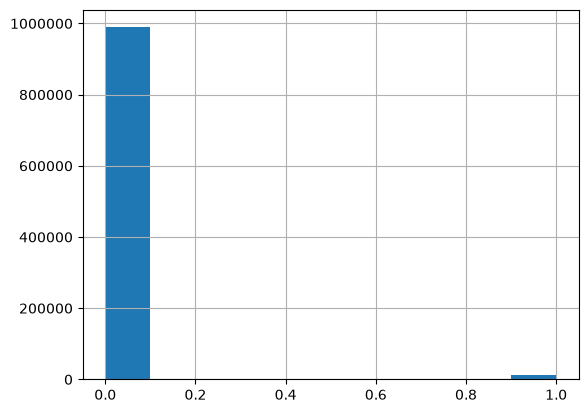

In [8]:
full_raw_data['fraud_bool'].hist()
plt.ticklabel_format(style='plain')
plt.show()

In [10]:
not_scam, scam = full_raw_data['fraud_bool'].value_counts()

In [11]:
for month_num in range(0,8):
    month_df = full_raw_data[full_raw_data['month'] == month_num]
    monthly_not_scam, monthly_scam = month_df['fraud_bool'].value_counts()
    print(f'Month: {month_num}')
    print(f'Not scam: {monthly_not_scam} / {(monthly_not_scam/(monthly_not_scam+monthly_scam)):.4f}')
    print(f'Scam:     {monthly_scam} / {(monthly_scam/(monthly_not_scam+monthly_scam)):.4f}')
    print(f'% Of All Scam: {(monthly_scam/scam):.3f}')
    print()
    

Month: 0
Not scam: 130940 / 0.9887
Scam:     1500 / 0.0113
% Of All Scam: 0.136

Month: 1
Not scam: 126422 / 0.9906
Scam:     1198 / 0.0094
% Of All Scam: 0.109

Month: 2
Not scam: 135781 / 0.9913
Scam:     1198 / 0.0087
% Of All Scam: 0.109

Month: 3
Not scam: 149544 / 0.9908
Scam:     1392 / 0.0092
% Of All Scam: 0.126

Month: 4
Not scam: 126239 / 0.9886
Scam:     1452 / 0.0114
% Of All Scam: 0.132

Month: 5
Not scam: 117912 / 0.9882
Scam:     1411 / 0.0118
% Of All Scam: 0.128

Month: 6
Not scam: 106718 / 0.9866
Scam:     1450 / 0.0134
% Of All Scam: 0.131

Month: 7
Not scam: 95415 / 0.9853
Scam:     1428 / 0.0147
% Of All Scam: 0.129



**Аналог той же операции в более правильном виде**

In [13]:
monthly_fraud_stats = (
    full_raw_data.groupby('month', as_index=False).agg(
        applications=('fraud_bool','size'),
        fraud_count=('fraud_bool','sum'),
        fraud_rate=('fraud_bool','mean'),
        ).sort_values('month'))

monthly_fraud_stats['legit_count'] = (
    monthly_fraud_stats['applications'] - monthly_fraud_stats['fraud_count']
)

total_fraud = monthly_fraud_stats['fraud_count'].sum()

monthly_fraud_stats['share_of_all_fraud'] = (monthly_fraud_stats['fraud_count']/ total_fraud)

monthly_fraud_stats

,month,applications,fraud_count,fraud_rate,legit_count,share_of_all_fraud
0,0,132440,1500,0.011326,130940,0.136005
1,1,127620,1198,0.009387,126422,0.108623
2,2,136979,1198,0.008746,135781,0.108623
3,3,150936,1392,0.009222,149544,0.126213
4,4,127691,1452,0.011371,126239,0.131653
5,5,119323,1411,0.011825,117912,0.127935
6,6,108168,1450,0.013405,106718,0.131472
7,7,96843,1428,0.014746,95415,0.129477


In [16]:
print(f"Кол-во дубликатов полного набора данных: ", full_raw_data.duplicated().sum())

Кол-во дубликатов полного набора данных:  0


По соотношению мошенников к немошенникам:
С 0 по 2 месяц наблюдается уменьшение доли мошеннических операций, также как и тенденцию спада их количества
с 3 по конец наблюдений видно увеличение доли мошеннических операций, также как и тендецию роста их количества

### Подсчет дубликатов, пропусков и -1 значений для каждой колонки

In [15]:
data_audit = pd.DataFrame({
    'dtype': full_raw_data.dtypes.astype(str),
    'rows': len(full_raw_data),
    'unique': full_raw_data.nunique(),
    'duplicated': full_raw_data.apply(lambda col: col.duplicated().sum()),
    'missing': full_raw_data.isna().sum(),
    '-1': full_raw_data.eq(-1).sum()
})

data_audit['missing_%'] = data_audit['missing']/data_audit['rows'] * 100
data_audit['-1_%'] = data_audit['-1']/data_audit['rows'] * 100

data_audit

,dtype,rows,unique,duplicated,missing,-1,missing_%,-1_%
fraud_bool,int64,1000000,2,999998,0,0,0.0,0.0000
income,float64,1000000,9,999991,0,0,0.0,0.0000
name_email_similarity,float64,1000000,998861,1139,0,0,0.0,0.0000
prev_address_months_count,int64,1000000,374,999626,0,712920,0.0,71.2920
current_address_months_count,int64,1000000,423,999577,0,4254,0.0,0.4254
customer_age,int64,1000000,9,999991,0,0,0.0,0.0000
days_since_request,float64,1000000,989330,10670,0,0,0.0,0.0000
intended_balcon_amount,float64,1000000,994971,5029,0,0,0.0,0.0000
payment_type,str,1000000,5,999995,0,0,0.0,0.0000
zip_count_4w,int64,1000000,6306,993694,0,0,0.0,0.0000
